# S(t) vs. S(t0+M)/S(t0) — seeing the difference on your real model

This notebook loads `rsf_final_model.pkl` and shows, side by side:

1. The model's raw predicted survival curve **S(t)** for one customer profile
   — this is what `predict_survival_function` gives you, anchored at t=0.
2. The **conditional** survival curve, given the customer has already survived
   to some tenure t0 — computed as `S(t) / S(t0)` for `t >= t0`.
3. A table comparing the naive churn probability `1 - S(t0+M)` against the
   correct conditional one `1 - S(t0+M)/S(t0)`, across several t0 values, so
   you can see exactly where and how much they diverge.

No retraining happens here — same model, same curve, just read two different ways.

In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model = joblib.load("rsf_final_model.pkl")
print(f"Model loaded. Expects {len(model.feature_names_in_)} features.")
print(f"Model's known time range: {model.unique_times_.min()} to {model.unique_times_.max()} months.")

Model loaded. Expects 28 features.
Model's known time range: 1.0 to 72.0 months.


## 1. Encode one example customer

Same encoding scheme your deployed app uses: manual one-hot encoding matched
exactly to `model.feature_names_in_`, so we don't rely on `pd.get_dummies`
guessing columns from a single row.

In [ ]:
NUMERIC_COLUMNS = ["SeniorCitizen", "MonthlyCharges"]

CATEGORICAL_COLUMNS = {
    "gender": ["Female", "Male"],
    "Partner": ["No", "Yes"],
    "Dependents": ["No", "Yes"],
    "PhoneService": ["No", "Yes"],
    "MultipleLines": ["No", "No phone service", "Yes"],
    "InternetService": ["DSL", "Fiber optic", "No"],
    "OnlineSecurity": ["No", "No internet service", "Yes"],
    "OnlineBackup": ["No", "No internet service", "Yes"],
    "DeviceProtection": ["No", "No internet service", "Yes"],
    "TechSupport": ["No", "No internet service", "Yes"],
    "StreamingTV": ["No", "No internet service", "Yes"],
    "StreamingMovies": ["No", "No internet service", "Yes"],
    "Contract": ["Month-to-month", "One year", "Two year"],
    "PaperlessBilling": ["No", "Yes"],
    "PaymentMethod": ["Bank transfer (automatic)", "Credit card (automatic)",
                       "Electronic check", "Mailed check"],
}

def encode_features(df_raw, model):
    out = pd.DataFrame(index=df_raw.index)
    for col in NUMERIC_COLUMNS:
        out[col] = pd.to_numeric(df_raw[col], errors="coerce")
    for col, categories in CATEGORICAL_COLUMNS.items():
        sorted_cats = sorted(categories)
        raw_values = df_raw[col].astype(str)
        for cat in sorted_cats[1:]:
            out[f"{col}_{cat}"] = (raw_values == cat).astype(int)
    return out.reindex(columns=list(model.feature_names_in_), fill_value=0)

# A month-to-month, fiber-optic, no-tech-support customer — a genuinely risky profile
example_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 1, "Partner": "No", "Dependents": "No",
    "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No",
    "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "Yes",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 90.0,
}])

X_encoded = encode_features(example_customer, model)
print("Encoded shape:", X_encoded.shape)

Encoded shape: (1, 28)


## 2. The model's raw S(t) — anchored at t=0

This is exactly what `predict_survival_function` returns: "starting from
nothing, what's the probability this customer profile survives to month t."

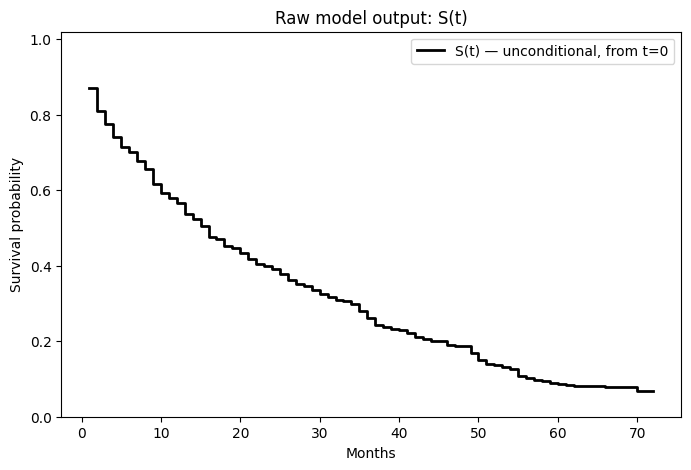

In [ ]:
surv_fn = model.predict_survival_function(X_encoded, return_array=False)[0]
t_grid = surv_fn.x
S_t = surv_fn.y

fig, ax = plt.subplots(figsize=(8, 5))
ax.step(t_grid, S_t, where="post", color="black", linewidth=2, label="S(t) — unconditional, from t=0")
ax.set_xlabel("Months")
ax.set_ylabel("Survival probability")
ax.set_title("Raw model output: S(t)")
ax.set_ylim(0, 1.02)
ax.legend()
plt.show()

## 3. The conditional curve for an already-active customer

Say this customer has already been with us **t0 = 12 months** and is still
active. The conditional survival curve, given that, is:

$$S(t \mid T > t_0) = \frac{S(t)}{S(t_0)} \quad \text{for } t \ge t_0$$

Notice this curve starts back at 1.0 at t0 — because *given* they made it to
month 12, their probability of "surviving from here" resets to certainty at
that starting point. That's the whole difference in one picture.

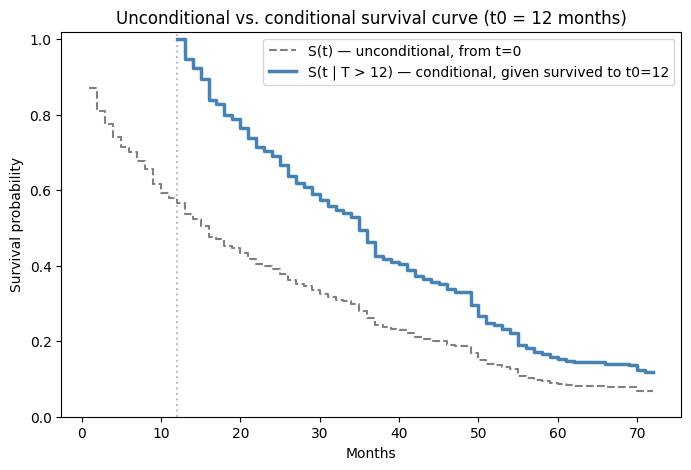

S(12) = 0.567  <- the model's confidence this customer profile makes it to month 12 at all


In [ ]:
t0 = 12.0

S_t0 = surv_fn(t0)
mask = t_grid >= t0
t_conditional = t_grid[mask]
S_conditional = surv_fn(t_conditional) / S_t0

fig, ax = plt.subplots(figsize=(8, 5))
ax.step(t_grid, S_t, where="post", color="gray", linewidth=1.5, linestyle="--",
        label="S(t) — unconditional, from t=0")
ax.step(t_conditional, S_conditional, where="post", color="steelblue", linewidth=2.5,
        label=f"S(t | T > {t0:.0f}) — conditional, given survived to t0={t0:.0f}")
ax.axvline(t0, color="gray", alpha=0.5, linestyle=":")
ax.set_xlabel("Months")
ax.set_ylabel("Survival probability")
ax.set_title(f"Unconditional vs. conditional survival curve (t0 = {t0:.0f} months)")
ax.set_ylim(0, 1.02)
ax.legend()
plt.show()

print(f"S({t0:.0f}) = {S_t0:.3f}  <- the model's confidence this customer profile makes it to month {t0:.0f} at all")

## 4. The number that actually matters: naive vs. conditional churn probability

For a fixed horizon **M = 3 months**, compare:

- **Naive** (what the app used to compute): `1 - S(t0 + M)` — ignores that the
  customer already survived to t0, reads the curve as if they were brand new.
- **Conditional** (the fix): `1 - S(t0+M)/S(t0)` — correctly accounts for the
  time they've already survived.

Watch how far apart these get as t0 grows — that gap **is** the size of the
bug the app had before we added this.

In [ ]:
M = 3.0
t0_values = [0, 6, 12, 24, 36, 48]

rows = []
for t0 in t0_values:
    t0c = min(max(t0, 0), t_grid.max())
    t1c = min(t0c + M, t_grid.max())

    s0 = surv_fn(t0c)
    s1 = surv_fn(t1c)

    naive_prob = 1 - surv_fn(t1c)          # ignores t0 entirely, always reads from t=0
    conditional_prob = 1 - (s1 / s0)          # correct: conditions on having survived to t0

    rows.append({
        "current_tenure_t0": t0,
        "S(t0)": round(s0, 3),
        "S(t0+M)": round(s1, 3),
        "naive_churn_prob_%": round(naive_prob * 100, 1),
        "conditional_churn_prob_%": round(conditional_prob * 100, 1),
        "difference_pct_pts": round((naive_prob - conditional_prob) * 100, 1),
    })

comparison_df = pd.DataFrame(rows)
comparison_df

,current_tenure_t0,S(t0),S(t0+M),naive_churn_prob_%,conditional_churn_prob_%,difference_pct_pts
0,0,0.870,0.776,22.4,10.8,11.6
1,6,0.702,0.616,38.4,12.3,26.2
2,12,0.567,0.507,49.3,10.6,38.7
3,24,0.391,0.350,65.0,10.4,54.5
4,36,0.262,0.233,76.7,11.3,65.5
5,48,0.187,0.141,85.9,24.6,61.3


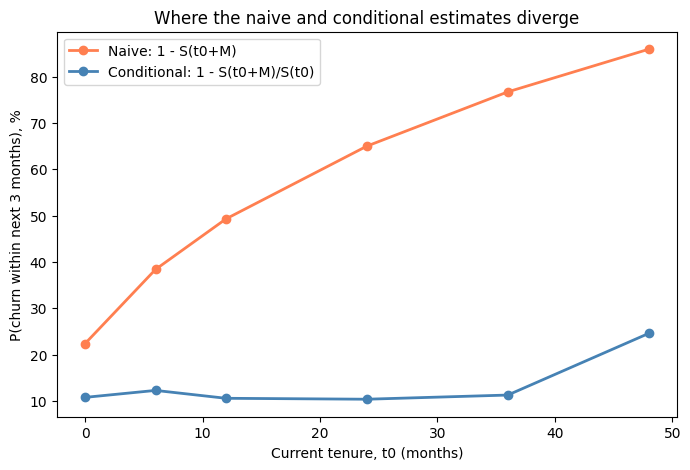

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(comparison_df["current_tenure_t0"], comparison_df["naive_churn_prob_%"],
        marker="o", color="coral", linewidth=2, label="Naive: 1 - S(t0+M)")
ax.plot(comparison_df["current_tenure_t0"], comparison_df["conditional_churn_prob_%"],
        marker="o", color="steelblue", linewidth=2, label="Conditional: 1 - S(t0+M)/S(t0)")
ax.set_xlabel("Current tenure, t0 (months)")
ax.set_ylabel(f"P(churn within next {M:.0f} months), %")
ax.set_title("Where the naive and conditional estimates diverge")
ax.legend()
plt.show()

## Takeaway

At `t0 = 0` the two numbers are identical — makes sense, since a brand-new
customer has no elapsed survival to condition on (`S(0) = 1`, so the formulas
collapse into each other). As `t0` grows, the naive version increasingly
**overstates** churn risk for long-tenured active customers, because it keeps
ignoring the fact that they've already demonstrated real staying power.

This is exactly the fix we're wiring into `model.py` / `api.py`: instead of
always reading the curve from t=0, the app now takes each customer's current
tenure as an input and reads the curve conditionally from that point forward.